# 04 — Qiskit Addon: Optimization Mapper (`qiskit-addon-opt-mapper`)

The **Optimization Mapper** addon describes an optimization problem in a form that does not depend on the solver. It then maps the problem to an operator for a quantum computer. The usual path has three steps:

1. a model with variables, an objective and constraints (`OptimizationProblem`),
2. a **QUBO** or **HUBO**: a quadratic (QUBO) or higher-order (HUBO) unconstrained binary optimization problem,
3. an **Ising Hamiltonian**: a sum of Pauli $Z$ products, stored as a `SparsePauliOp`.

The package replaces the modeling part of `qiskit-optimization` [[1]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/00_migrate_from_qiskit_optimization.html). It adds **spin variables** (values $\pm 1$) and **higher-order terms** (products of $k \ge 3$ variables).

**Based on** the `qiskit-addon-opt-mapper` how-to guides:

* modeling with `OptimizationProblem` [[2]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/01_optimization_problem.html),
* translation to and from docplex [[3]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/04_translate_docplex.html),
* converters [[5]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/02_converters_for_optimization_problems.html),
* validation with classical solvers [[7]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/03_validate_with_solvers.html).

Section 8 is our own example. It solves MaxCut with QAOA (Quantum Approximate Optimization Algorithm), built from the Qiskit API [[9]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.qaoa_ansatz), [[11]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator), [[12]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler).

Installation:

```bash
pip install "qiskit-addon-opt-mapper"
```

**Package layout (v0.1.0)**

| Module | What it contains |
|---|---|
| `qiskit_addon_opt_mapper` | `OptimizationProblem`, `INFINITY`, exceptions |
| `.problems` | variables (`VarType`: CONTINUOUS / BINARY / INTEGER / SPIN), linear / quadratic / higher-order expressions and constraints |
| `.applications` | ready-made models: `Maxcut`, `Knapsack`, `Tsp`, `VertexCover`, `IndependentSet`, `Clique`, `GraphPartition`, `NumberPartition`, `SetPacking`, `ExactCover`, `BinPacking`, `VehicleRouting`, `SKModel` |
| `.converters` | `OptimizationProblemToQubo`, `OptimizationProblemToHubo`, `IntegerToBinary`, `InequalityToEquality`, `LinearInequalityToPenalty`, `EqualityToPenalty`, `MaximizeToMinimize`, `MinimizeToMaximize`, `BinaryToSpin`, `SpinToBinary` |
| `.translators` | `to_ising`, `to_docplex_mp`, `from_docplex_mp` |
| `.solvers` | `ScipyMilpSolver`, `CplexSolver`, `GurobiSolver` (the last two need optional commercial packages) |

**Contents**

1. Setup
2. Modeling an `OptimizationProblem`
3. Translating to and from docplex
4. Built-in applications
5. Converters: from constrained problems to QUBO / HUBO
6. Mapping to an Ising Hamiltonian (`SparsePauliOp`)
7. Solving classically
8. Solving MaxCut with QAOA
9. Summary and references

## 1. Setup

In [1]:
import itertools
import importlib.metadata as md

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

import qiskit
from qiskit_addon_opt_mapper import INFINITY, OptimizationProblem
from qiskit_addon_opt_mapper.problems import VarType

for pkg in ["qiskit", "qiskit-addon-opt-mapper", "docplex", "networkx", "scipy"]:
    print(f"{pkg:26s} {md.version(pkg)}")

qiskit                     2.5.2
qiskit-addon-opt-mapper    0.1.0
docplex                    2.32.264
networkx                   3.4.2
scipy                      1.15.3


## 2. Modeling an `OptimizationProblem`

`OptimizationProblem` is the central class [[2]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/01_optimization_problem.html). A problem has three parts:

* **Variables**: `binary_var`, `integer_var`, `continuous_var` and `spin_var`. The helpers `*_var_list` and `*_var_dict` create many variables at once.
* One **objective**, set with `minimize(...)` or `maximize(...)`. It has a `constant`, a `linear` part, a `quadratic` part and a `higher_order` part. Coefficients can be dicts keyed by variable names or indices, lists, or NumPy arrays.
* Any number of **constraints**: `linear_constraint`, `quadratic_constraint` and `higher_order_constraint`. The sense is `"<="`, `">="` or `"=="`.

Higher-order terms use a dict `{order k: coefficients}`. The coefficients are a dict `{(i, j, l, ...): c}` or a dense array of shape `(n,)*k`.

In [2]:
prob = OptimizationProblem("demo")

# Variables of every supported type
x = prob.binary_var("x")
y = prob.binary_var("y")
z = prob.integer_var(lowerbound=0, upperbound=3, name="z")
s = prob.spin_var("s")                      # takes values -1 or +1
w = prob.continuous_var(lowerbound=0, upperbound=INFINITY, name="w")

# Objective with constant, linear, quadratic and a cubic (3rd order) term
prob.minimize(
    constant=3,
    linear={"x": 1, "z": -2, "w": 1},
    quadratic={("x", "y"): 2, ("z", "z"): 1},
    higher_order={3: {("x", "y", "z"): 4}},
)

# Constraints
prob.linear_constraint(linear={"x": 1, "y": 1, "z": 1}, sense="<=", rhs=3, name="lin")
prob.quadratic_constraint(linear={"w": 1}, quadratic={("x", "z"): 1}, sense=">=", rhs=1, name="quad")
prob.higher_order_constraint(
    linear={"x": 1},
    higher_order={3: {("x", "y", "s"): 1}},
    sense=">=",
    rhs=0,
    name="hoc",
)

print(prob.prettyprint())

Problem name: demo

Minimize
  4*x*y*z + 2*x*y + z^2 + w + x - 2*z + 3

Subject to
  Linear constraints (1)
    x + y + z <= 3  'lin'

  Quadratic constraints (1)
    x*z + w >= 1  'quad'

  Higher-order constraints (1)
    s*x*y + x >= 0  'hoc'

  Integer variables (1)
    0 <= z <= 3

  Continuous variables (1)
    0 <= w

  Binary variables (2)
    x y

  Spin variables (1)
    -1 <= s <= 1



The problem object can also be inspected in code:

In [3]:
print(repr(prob))
print("variables:", [(v.name, v.vartype.name, v.lowerbound, v.upperbound) for v in prob.variables])
print("#binary =", prob.get_num_binary_vars(), " #integer =", prob.get_num_integer_vars(),
      " #spin =", prob.get_num_spin_vars(), " #continuous =", prob.get_num_continuous_vars())
print("objective sense:", prob.objective.sense.name)
print("linear coeffs   :", prob.objective.linear.to_dict(use_name=True))
print("quadratic coeffs:", prob.objective.quadratic.to_dict(use_name=True))
print("cubic coeffs    :", prob.objective.higher_order[3].to_dict(use_name=True))

<OptimizationProblem: minimize 4*x*y*z + 2*x*y + z^2 + w + x - 2*z + 3, 5 variables, 3 constraints, 'demo'>
variables: [('x', 'BINARY', 0, 1), ('y', 'BINARY', 0, 1), ('z', 'INTEGER', 0, 3), ('s', 'SPIN', -1, 1), ('w', 'CONTINUOUS', 0, 1e+20)]
#binary = 2  #integer = 1  #spin = 1  #continuous = 1
objective sense: MINIMIZE
linear coeffs   : {'x': 1.0, 'z': -2.0, 'w': 1.0}
quadratic coeffs: {('x', 'y'): np.float64(2.0), ('z', 'z'): np.float64(1.0)}
cubic coeffs    : {('x', 'y', 'z'): 4.0}


`objective.evaluate(x)` evaluates the objective at a point. `is_feasible` and `get_feasibility_info` check the bounds and all constraints. The point uses the order of `prob.variables`, here `[x, y, z, s, w]`.

In [4]:
for point in ([1, 0, 2, 1, 0.5], [1, 1, 2, -1, 0.0]):
    feas, bad_vars, bad_cons = prob.get_feasibility_info(point)
    print(point, "objective =", prob.objective.evaluate(point),
          "| feasible:", feas, "| violated:", [c.name for c in bad_cons])

[1, 0, 2, 1, 0.5] objective = 4.5 | feasible: True | violated: []
[1, 1, 2, -1, 0.0] objective = 14.0 | feasible: False | violated: ['lin']


The same kind of model can use index-based, list-based or array-based coefficients. This form is convenient when the data comes from NumPy. An order-3 coefficient tensor has shape `(n, n, n)`:

In [5]:
p2 = OptimizationProblem("array_form")
p2.binary_var_list(4, name="b")            # b0 .. b3
h3 = np.zeros((4, 4, 4))
h3[0, 1, 2] = 4.0                           # 4 * b0*b1*b2
Q = np.zeros((4, 4)); Q[0, 3] = -1.0        # -1 * b0*b3
p2.maximize(constant=1, linear=[1, 0, 0, 2], quadratic=Q, higher_order={3: h3})
p2.linear_constraint([1, 1, 1, 1], "==", 2, name="pick_two")
print(p2.prettyprint())

Problem name: array_form

Maximize
  4*b0*b1*b2 - b0*b3 + b0 + 2*b3 + 1

Subject to
  Linear constraints (1)
    b0 + b1 + b2 + b3 == 2  'pick_two'

  Binary variables (4)
    b0 b1 b2 b3



## 3. Translating to and from docplex

`to_docplex_mp` and `from_docplex_mp` convert between `OptimizationProblem` and an IBM **docplex** `Model` [[3]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/04_translate_docplex.html). Docplex is a pure Python modeling library. It does not need CPLEX to build models. With these functions you can:

* write a model in the algebraic syntax of docplex,
* export a model to an LP file (a standard text format for optimization models).

Docplex models are at most quadratic and have no spin type. So higher-order terms and spin variables cannot be exported.

In [6]:
from docplex.mp.model import Model
from qiskit_addon_opt_mapper.translators import from_docplex_mp, to_docplex_mp

mdl = Model("docplex_example")
xs = mdl.binary_var_list(3, name="x")
t = mdl.integer_var(lb=0, ub=5, name="t")
mdl.maximize(xs[0] + 2 * xs[1] + 3 * xs[2] + t - xs[0] * xs[1])
mdl.add_constraint(xs[0] + xs[1] + xs[2] + t <= 4, "capacity")

op_from_dp = from_docplex_mp(mdl)
print(op_from_dp.prettyprint())

Problem name: docplex_example

Maximize
  -x_0*x_1 + t + x_0 + 2*x_1 + 3*x_2

Subject to
  Linear constraints (1)
    t + x_0 + x_1 + x_2 <= 4  'capacity'

  Integer variables (1)
    0 <= t <= 5

  Binary variables (3)
    x_0 x_1 x_2



In [7]:
# ... and back to docplex, exported as an LP-format string
print(to_docplex_mp(op_from_dp).export_as_lp_string())

\ This file has been generated by DOcplex
\ ENCODING=ISO-8859-1
\Problem name: docplex_example

Maximize
 obj: x_0 + 2 x_1 + 3 x_2 + t + [ - 2 x_0*x_1 ]/2
Subject To
 capacity: x_0 + x_1 + x_2 + t <= 4

Bounds
 0 <= x_0 <= 1
 0 <= x_1 <= 1
 0 <= x_2 <= 1
       t <= 5

Binaries
 x_0 x_1 x_2

Generals
 t
End



In [8]:
# docplex has no spin variables and no terms beyond quadratic:
for label, model in [("prob (has a spin variable)", prob), ("p2 (has a cubic term)", p2)]:
    try:
        to_docplex_mp(model)
    except Exception as err:
        print(f"{label}: {type(err).__name__}: {err}")

prob (has a spin variable): OptimizationError: Spin variables are not supported in docplex.md model export.
p2 (has a cubic term): OptimizationError: Higher-order objective terms are not supported in docplex.md model export.


## 4. Built-in applications

The `applications` module [[4]](https://qiskit.github.io/qiskit-addon-opt-mapper/apidocs/qiskit_addon_opt_mapper.applications.html) contains ready-made models of common combinatorial problems. Each application has these methods:

* `to_optimization_problem()` builds the `OptimizationProblem`.
* `interpret(x)` turns a binary solution vector (`np.ndarray`) into an answer for the specific problem.
* `sample_most_likely(...)` is a static helper. It picks the most likely bitstring from counts, a `QuasiDistribution` or a `Statevector`.
* `draw(result)` exists for graph applications. It draws the graph with rustworkx and matplotlib.

In [9]:
import qiskit_addon_opt_mapper.applications as apps
import inspect

for name in apps.__all__:
    cls = getattr(apps, name)
    print(f"{name:30s}{inspect.signature(cls.__init__)}")

BinPacking                    (self, weights: list[int], max_weight: int, max_number_of_bins: int | None = None) -> None
Clique                        (self, graph: networkx.classes.graph.Graph | numpy.ndarray | list, size: int | None = None) -> None
ExactCover                    (self, subsets: list[list[int]]) -> None
GraphOptimizationApplication  (self, graph: networkx.classes.graph.Graph | numpy.ndarray | list | rustworkx.PyGraph) -> None
GraphPartition                (self, graph: networkx.classes.graph.Graph | numpy.ndarray | list | rustworkx.PyGraph) -> None
IndependentSet                (self, graph: networkx.classes.graph.Graph | numpy.ndarray | list | rustworkx.PyGraph) -> None
Knapsack                      (self, values: list[int], weights: list[int], max_weight: int) -> None
Maxcut                        (self, graph: networkx.classes.graph.Graph | numpy.ndarray | list | rustworkx.PyGraph) -> None
NumberPartition               (self, number_set: list[int]) -> None
Optimizat

### 4.1 Knapsack

We choose items with values $v_i$ and weights $w_i$. The goal is maximum total value, with total weight at most $W$. The model has a linear objective and one linear inequality.

In [10]:
from qiskit_addon_opt_mapper.applications import Knapsack

values, weights, max_weight = [3, 4, 5, 6], [2, 3, 4, 5], 7
knapsack = Knapsack(values=values, weights=weights, max_weight=max_weight)
kp = knapsack.to_optimization_problem()
print(kp.prettyprint())

Problem name: Knapsack

Maximize
  3*x_0 + 4*x_1 + 5*x_2 + 6*x_3

Subject to
  Linear constraints (1)
    2*x_0 + 3*x_1 + 4*x_2 + 5*x_3 <= 7  'c0'

  Binary variables (4)
    x_0 x_1 x_2 x_3



### 4.2 Graph applications: independent set, vertex cover, max-cut

Graph applications accept a `networkx.Graph`, a `rustworkx.PyGraph`, an adjacency matrix or an edge list. We use one small graph in this section and draw it with networkx.

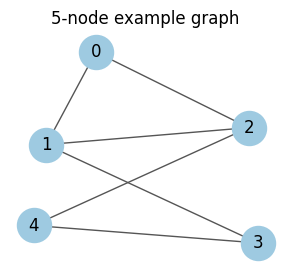

In [11]:
G = nx.Graph()
G.add_edges_from([(0, 1), (0, 2), (1, 2), (1, 3), (2, 4), (3, 4)])
pos = nx.spring_layout(G, seed=7)

fig, ax = plt.subplots(figsize=(3.5, 3))
nx.draw(G, pos, ax=ax, with_labels=True, node_color="#9ecae1", edge_color="#555", node_size=600)
ax.set_title("5-node example graph")
plt.show()

In [12]:
from qiskit_addon_opt_mapper.applications import IndependentSet, Maxcut, VertexCover

for app_cls in (IndependentSet, VertexCover, Maxcut):
    print(app_cls(G).to_optimization_problem().prettyprint(), "\n" + "-" * 70)

Problem name: Independent set

Maximize
  x_0 + x_1 + x_2 + x_3 + x_4

Subject to
  Linear constraints (6)
    x_0 + x_1 <= 1  'c0'
    x_0 + x_2 <= 1  'c1'
    x_1 + x_2 <= 1  'c2'
    x_1 + x_3 <= 1  'c3'
    x_2 + x_4 <= 1  'c4'
    x_3 + x_4 <= 1  'c5'

  Binary variables (5)
    x_0 x_1 x_2 x_3 x_4
 
----------------------------------------------------------------------
Problem name: Vertex cover

Minimize
  x_0 + x_1 + x_2 + x_3 + x_4

Subject to
  Linear constraints (6)
    x_0 + x_1 >= 1  'c0'
    x_0 + x_2 >= 1  'c1'
    x_1 + x_2 >= 1  'c2'
    x_1 + x_3 >= 1  'c3'
    x_2 + x_4 >= 1  'c4'
    x_3 + x_4 >= 1  'c5'

  Binary variables (5)
    x_0 x_1 x_2 x_3 x_4
 
----------------------------------------------------------------------
Problem name: Max-cut

Maximize
  -2*x_0*x_1 - 2*x_0*x_2 - 2*x_1*x_2 - 2*x_1*x_3 - 2*x_2*x_4 - 2*x_3*x_4 + 2*x_0
  + 3*x_1 + 3*x_2 + 2*x_3 + 2*x_4

Subject to
  No constraints

  Binary variables (5)
    x_0 x_1 x_2 x_3 x_4
 
---------------------

`IndependentSet` and `VertexCover` have linear objectives and one linear constraint per edge. `Maxcut` is an unconstrained quadratic problem, so it is already a QUBO. Its objective is $\sum_{(i,j)} w_{ij}(x_i + x_j - 2x_ix_j)$.

## 5. Converters: from constrained problems to QUBO / HUBO

Quantum heuristics such as QAOA need an **unconstrained binary** problem. Converters [[5]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/02_converters_for_optimization_problems.html) rewrite the problem step by step. Each converter also stores how to map a solution back (`interpret`).

| Converter | Effect |
|---|---|
| `LinearInequalityToPenalty` | turns special inequalities, such as $x_i + x_j \le 1$, into penalties without slack variables |
| `InequalityToEquality` | adds integer slack variables: $a^Tx \le b \;\to\; a^Tx + s = b$ |
| `IntegerToBinary` | binary expansion of bounded integer variables |
| `SpinToBinary` / `BinaryToSpin` | $s = 1 - 2b$ |
| `EqualityToPenalty` | $a^Tx = b \;\to\; +P\,(a^Tx-b)^2$ added to the objective |
| `MaximizeToMinimize` / `MinimizeToMaximize` | flip the objective sense |

A **slack variable** $s \ge 0$ turns an inequality into an equality. A **penalty** term $P\,(\dots)^2$ with factor $P > 0$ raises the objective when a constraint is violated.

`OptimizationProblemToQubo` chains these converters for quadratic problems with linear constraints. `OptimizationProblemToHubo` does the same and also accepts higher-order objectives and constraints.

### 5.1 One step at a time (knapsack)

In [13]:
from qiskit_addon_opt_mapper.converters import (
    EqualityToPenalty, InequalityToEquality, IntegerToBinary, MaximizeToMinimize,
    OptimizationProblemToHubo, OptimizationProblemToQubo,
)

step1 = InequalityToEquality().convert(kp)          # adds integer slack c0@int_slack
print(step1.prettyprint(), "\n" + "-" * 70)
step2 = IntegerToBinary().convert(step1)            # slack -> binary bits
print(step2.prettyprint(), "\n" + "-" * 70)
step3 = EqualityToPenalty(penalty=10).convert(step2)
step4 = MaximizeToMinimize().convert(step3)
print("after penalty + sense flip:", repr(step4))

Problem name: Knapsack

Maximize
  3*x_0 + 4*x_1 + 5*x_2 + 6*x_3

Subject to
  Linear constraints (1)
    c0@int_slack + 2*x_0 + 3*x_1 + 4*x_2 + 5*x_3 == 7  'c0'

  Integer variables (1)
    0 <= c0@int_slack <= 7

  Binary variables (4)
    x_0 x_1 x_2 x_3
 
----------------------------------------------------------------------
Problem name: Knapsack

Maximize
  3*x_0 + 4*x_1 + 5*x_2 + 6*x_3

Subject to
  Linear constraints (1)
    c0@int_slack@0 + 2*c0@int_slack@1 + 4*c0@int_slack@2 + 2*x_0 + 3*x_1 + 4*x_2
    + 5*x_3 == 7  'c0'

  Binary variables (7)
    x_0 x_1 x_2 x_3 c0@int_slack@0 c0@int_slack@1 c0@int_slack@2
 
----------------------------------------------------------------------
after penalty + sense flip: <OptimizationProblem: minimize 10*c0@int_slack@0^2 + 40*c0@int_slack@0*c0@int_sla..., 7 variables, 0 constraints, ''>


### 5.2 The all-in-one QUBO converter

With `penalty=None` (the default), the converter chooses the penalty factor automatically. The value is $1 + (\text{upper bound} - \text{lower bound})$ of the objective. `interpret` maps a QUBO solution back to the original variables and drops the slack bits.

In [14]:
qubo_conv = OptimizationProblemToQubo()
kp_qubo = qubo_conv.convert(kp)
print("variables:", [v.name for v in kp_qubo.variables])
print("constraints:", kp_qubo.get_num_linear_constraints(), "| sense:", kp_qubo.objective.sense.name)
print(kp_qubo.prettyprint(wrap=100))

variables: ['x_0', 'x_1', 'x_2', 'x_3', 'c0@int_slack@0', 'c0@int_slack@1', 'c0@int_slack@2']
constraints: 0 | sense: MINIMIZE
Problem name: 

Minimize
  19*c0@int_slack@0^2 + 76*c0@int_slack@0*c0@int_slack@1 + 152*c0@int_slack@0*c0@int_slack@2
  + 76*c0@int_slack@1^2 + 304*c0@int_slack@1*c0@int_slack@2 + 304*c0@int_slack@2^2
  + 76*x_0*c0@int_slack@0 + 152*x_0*c0@int_slack@1 + 304*x_0*c0@int_slack@2 + 76*x_0^2 + 228*x_0*x_1
  + 304*x_0*x_2 + 380*x_0*x_3 + 114*x_1*c0@int_slack@0 + 228*x_1*c0@int_slack@1
  + 456*x_1*c0@int_slack@2 + 171*x_1^2 + 456*x_1*x_2 + 570*x_1*x_3 + 152*x_2*c0@int_slack@0
  + 304*x_2*c0@int_slack@1 + 608*x_2*c0@int_slack@2 + 304*x_2^2 + 760*x_2*x_3
  + 190*x_3*c0@int_slack@0 + 380*x_3*c0@int_slack@1 + 760*x_3*c0@int_slack@2 + 475*x_3^2
  - 266*c0@int_slack@0 - 532*c0@int_slack@1 - 1064*c0@int_slack@2 - 535*x_0 - 802*x_1 - 1069*x_2
  - 1336*x_3 + 931

Subject to
  No constraints

  Binary variables (7)
    x_0 x_1 x_2 x_3 c0@int_slack@0 c0@int_slack@1 c0@int_slack@

The QUBO converter does not accept higher-order input. For that case, use `OptimizationProblemToHubo`:

In [15]:
print("QUBO compatible?", qubo_conv.is_compatible(prob))
print(OptimizationProblemToQubo.get_compatibility_msg(prob))

# The HUBO converter does not support continuous variables, so take a discrete copy of `prob`
hp = OptimizationProblem("discrete_demo")
hp.binary_var("x"); hp.binary_var("y"); hp.integer_var(0, 3, "z"); hp.spin_var("s")
hp.minimize(constant=3, linear={"x": 1, "z": -2}, quadratic={("x", "y"): 2},
            higher_order={3: {("x", "y", "z"): 4}})
hp.linear_constraint({"x": 1, "y": 1}, "<=", 1, name="c0")
hp.higher_order_constraint(linear={"x": 1}, higher_order={3: {("x", "y", "s"): 1}},
                           sense=">=", rhs=0, name="hoc")

hubo_conv = OptimizationProblemToHubo()
hubo = hubo_conv.convert(hp)
print(hubo.prettyprint(wrap=100))

QUBO compatible? False
Continuous variables are not supported. Higher order objective functions are not supported. Quadratic constraints are not supported. Higher order constraints are not supported. 
Problem name: 

Minimize
  128*s@bin^2*x^2*y^2 - 128*s@bin*x^2*y^2 - 128*s@bin*x^2*y + 32*x^2*y^2
  + 128*hoc@int_slack@0*s@bin*x*y + 128*hoc@int_slack@1*s@bin*x*y + 64*x^2*y
  - 64*hoc@int_slack@0*x*y - 64*hoc@int_slack@1*x*y + 4*x*y*z@0 + 8*x*y*z@1 + 32*hoc@int_slack@0^2
  + 64*hoc@int_slack@0*hoc@int_slack@1 + 32*hoc@int_slack@1^2 - 64*x*hoc@int_slack@0
  - 64*x*hoc@int_slack@1 + 32*x^2 + 12*x*y + x - 2*z@0 - 4*z@1 + 3

Subject to
  No constraints

  Binary variables (7)
    x y z@0 z@1 s@bin hoc@int_slack@0 hoc@int_slack@1



After the conversion, every variable is binary:

* `z@0` and `z@1` hold the bits of `z`.
* `s@bin` is the spin `s` mapped to a binary variable.
* `hoc@int_slack@0` and `hoc@int_slack@1` are the slack bits of the higher-order inequality `hoc`.

The objective contains terms up to degree 6.

The reverse direction also exists. `BinaryToSpin` rewrites a binary problem with $\pm 1$ spins. This is the natural form for Ising models:

In [16]:
from qiskit_addon_opt_mapper.converters import BinaryToSpin

mc_problem = Maxcut(G).to_optimization_problem()
print(BinaryToSpin().convert(mc_problem).prettyprint())

Problem name: Max-cut

Maximize
  -0.5*x_0@spin*x_1@spin - 0.5*x_0@spin*x_2@spin - 0.5*x_1@spin*x_2@spin
  - 0.5*x_1@spin*x_3@spin - 0.5*x_2@spin*x_4@spin - 0.5*x_3@spin*x_4@spin + 3

Subject to
  No constraints

  Spin variables (5)
    -1 <= x_0@spin <= 1
    -1 <= x_1@spin <= 1
    -1 <= x_2@spin <= 1
    -1 <= x_3@spin <= 1
    -1 <= x_4@spin <= 1


## 6. Mapping to an Ising Hamiltonian (`SparsePauliOp`)

`to_ising(problem)` [[6]](https://qiskit.github.io/qiskit-addon-opt-mapper/stubs/qiskit_addon_opt_mapper.translators.to_ising.html), also available as `problem.to_ising()`, needs an **unconstrained** problem. All variables must be binary, or all must be spin. The function returns `(qubit_op, offset)`. A binary variable maps as $x_i = (1 - Z_i)/2$, and variable $i$ maps to qubit $i$.

* For a **minimization**, $\langle b|H|b\rangle + \text{offset} = f(b)$.
* For a **maximization**, the sign is flipped: $\langle b|H|b\rangle + \text{offset} = -f(b)$. So the ground state of $H$ is always the optimum.

In [17]:
from qiskit_addon_opt_mapper.translators import to_ising

H_mc, off_mc = to_ising(mc_problem)
print(H_mc)
print("offset =", off_mc)

SparsePauliOp(['IIIZZ', 'IIZIZ', 'IIZZI', 'IZIZI', 'ZIZII', 'ZZIII'],
              coeffs=[0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j])
offset = -3.0


The Hamiltonian is diagonal in the computational basis. We check it against the objective on all $2^n$ bitstrings. Qiskit uses little-endian qubit order, so bit $i$ of the basis-state index is variable $x_i$:

In [18]:
def diag_energies(op):
    # Diagonal of a Z-only SparsePauliOp, without building the dense matrix.
    n = op.num_qubits
    idx = np.arange(2**n)
    bits = (idx[:, None] >> np.arange(n)) & 1          # bits[k, i] = value of qubit i
    E = np.zeros(2**n)
    for pauli, c in zip(op.paulis, op.coeffs):
        zmask = pauli.z.astype(int)
        parity = (bits @ zmask) % 2
        E += np.real(c) * (1 - 2 * parity)
    return E, bits

def check_ising(problem, op, offset):
    E, bits = diag_energies(op)
    sign = problem.objective.sense.value                # +1 minimize, -1 maximize
    f = np.array([problem.objective.evaluate(b) for b in bits])
    return np.allclose(E + offset, sign * f)

print("MaxCut Ising consistent with objective:", check_ising(mc_problem, H_mc, off_mc))

H_hubo, off_hubo = to_ising(hubo)
print(f"HUBO -> {H_hubo.num_qubits} qubits, {len(H_hubo)} Pauli terms, "
      f"max weight {max(p.z.sum() for p in H_hubo.paulis)}")
print("HUBO Ising consistent with objective:", check_ising(hubo, H_hubo, off_hubo))

MaxCut Ising consistent with objective:

 True
HUBO -> 7 qubits, 25 Pauli terms, max weight 4
HUBO Ising consistent with objective: True


A constrained problem must be converted first. Otherwise `to_ising` raises an error:

In [19]:
from qiskit_addon_opt_mapper import OptimizationError
try:
    to_ising(kp)
except OptimizationError as err:
    print("OptimizationError:", err)

H_kp, off_kp = to_ising(kp_qubo)
print(f"knapsack QUBO -> {H_kp.num_qubits} qubits, {len(H_kp)} terms, offset {off_kp:.1f}")

OptimizationError: There must be no constraint in the problem. You can use `OptimizationProblemToQubo` converter to convert constraints to penalty terms of the objective function.
knapsack QUBO -> 7 qubits, 28 terms, offset 580.0


## 7. Solving classically

### 7.1 `ScipyMilpSolver`

`ScipyMilpSolver` [[8]](https://qiskit.github.io/qiskit-addon-opt-mapper/stubs/qiskit_addon_opt_mapper.solvers.ScipyMilpSolver.html) wraps `scipy.optimize.milp` (mixed-integer linear programming). The workflow follows the validation how-to [[7]](https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/03_validate_with_solvers.html). It handles **linear** objectives and linear constraints over continuous, integer and binary variables. `CplexSolver` and `GurobiSolver` handle quadratic models. They need the optional `cplex` or `gurobipy` packages, which are not installed in this environment. Solvers return a `SolverResult` with `.x`, `.fval`, `.status` and `.variables_dict`.

In [20]:
from qiskit_addon_opt_mapper.solvers import CplexSolver, ScipyMilpSolver

milp = ScipyMilpSolver()
res_kp = milp.solve(kp)
print(res_kp.prettyprint())
print("chosen items:", knapsack.interpret(res_kp.x))
print("variables_dict:", res_kp.variables_dict)

# Independent set is also linear -> MILP can solve it
mis = IndependentSet(G)
res_mis = milp.solve(mis.to_optimization_problem())
print("\nmax independent set:", mis.interpret(res_mis.x), "| size", res_mis.fval)

# Quadratic problems are rejected; optional solvers raise if their package is missing
print("\nMILP compatible with MaxCut?", milp.is_compatible(mc_problem), "-", milp.get_compatibility_msg(mc_problem))
try:
    CplexSolver()
except Exception as err:
    print(type(err).__name__, ":", str(err).splitlines()[0])

objective function value: 9.0
variable values: x_0=0, x_1=1, x_2=1, x_3=0
status: SUCCESS
chosen items: [1, 2]
variables_dict: {'x_0': 0, 'x_1': 1, 'x_2': 1, 'x_3': 0}

max independent set: [0, 3] | size 2.0

MILP compatible with MaxCut? False - scipy.milp supports only linear objective function
MissingOptionalLibraryError : "The 'CPLEX' library is required to use 'CplexSolver'. You can install it with 'pip install 'qiskit-addon-opt-mapper[cplex]''."


### 7.2 Brute force on the QUBO / Ising form

The problems here are small. So we can enumerate all bitstrings exactly with the diagonal of the Ising Hamiltonian. This also confirms that the penalty QUBO has the same optimum as the original constrained problem.

In [21]:
def brute_force(op, offset):
    E, bits = diag_energies(op)
    k = int(np.argmin(E))
    return bits[k], E[k] + offset, E + offset

x_qubo, e_qubo, _ = brute_force(H_kp, off_kp)
x_orig = qubo_conv.interpret(x_qubo)                    # drop slack bits
print("QUBO optimum bits     :", x_qubo)
print("mapped back to problem:", x_orig, "-> items", knapsack.interpret(np.asarray(x_orig)))
print("knapsack value        :", kp.objective.evaluate(x_orig), "| feasible:", kp.is_feasible(x_orig))

QUBO optimum bits     : [0 1 1 0 0 0 0]
mapped back to problem: [0. 1. 1. 0.] -> items [1, 2]
knapsack value        : 9.0 | feasible: True


**The penalty size matters.** If the penalty is too small, the QUBO minimum can be infeasible for the original problem. Here we scan the penalty for the independent-set QUBO:

In [22]:
mis_prob = mis.to_optimization_problem()
for P in [0.25, 0.5, 1.0, 2.0, None]:
    conv = OptimizationProblemToQubo(penalty=P)
    q = conv.convert(mis_prob)
    xb, _, _ = brute_force(*to_ising(q))
    xo = np.asarray(conv.interpret(xb))
    print(f"penalty={str(P):5s} -> nodes {mis.interpret(xo)}, size {int(mis_prob.objective.evaluate(xo))}, "
          f"feasible={mis_prob.is_feasible(xo)}")

penalty=0.25  -> nodes [0, 1, 2, 3, 4], size 5, feasible=False
penalty=0.5   -> nodes [0, 2, 3], size 3, feasible=False
penalty=1.0   -> nodes [0, 3], size 2, feasible=True
penalty=2.0   -> nodes [0, 3], size 2, feasible=True
penalty=None  -> nodes [0, 3], size 2, feasible=True


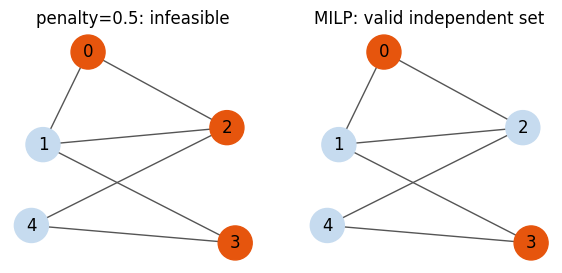

In [23]:
P_bad = 0.5
conv_bad = OptimizationProblemToQubo(penalty=P_bad)
x_bad = np.asarray(conv_bad.interpret(brute_force(*to_ising(conv_bad.convert(mis_prob)))[0]))
x_good = np.asarray(res_mis.x)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, xv, title in zip(axes, [x_bad, x_good], [f"penalty={P_bad}: infeasible", "MILP: valid independent set"]):
    colors = ["#e6550d" if v > 0.5 else "#c6dbef" for v in xv]
    nx.draw(G, pos, ax=ax, with_labels=True, node_color=colors, node_size=600, edge_color="#555")
    ax.set_title(title)
plt.show()

## 8. Solving MaxCut with QAOA

QAOA prepares a parametrized state with alternating cost and mixer layers. A classical optimizer then tunes the parameters. This section runs the full workflow on a small weighted graph:

1. Build the problem with `Maxcut` and map it to the cost Hamiltonian $H_C$ with `to_ising`.
2. Build the QAOA circuit $|\gamma,\beta\rangle = \prod_{l=1}^{p} e^{-i\beta_l H_M} e^{-i\gamma_l H_C} |+\rangle^{\otimes n}$ with `qiskit.circuit.library.qaoa_ansatz` [[9]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.qaoa_ansatz). Here $H_M = \sum_i X_i$ is the mixer and $p$ is the number of layers.
3. Minimize $\langle H_C\rangle$ with `StatevectorEstimator` [[11]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator) and `scipy.optimize.minimize`.
4. Sample the optimized circuit with `StatevectorSampler` [[12]](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler). Decode the bitstrings with `sample_most_likely` and `Maxcut.interpret`.

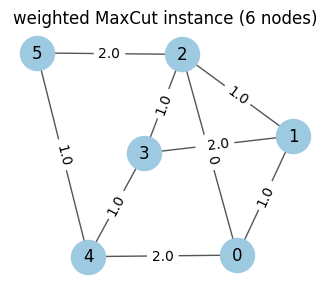

Problem name: Max-cut

Maximize
  -2*x_0*x_1 - 2*x_0*x_2 - 4*x_0*x_4 - 2*x_1*x_2 - 4*x_1*x_3 - 2*x_2*x_3
  - 4*x_2*x_5 - 2*x_3*x_4 - 2*x_4*x_5 + 4*x_0 + 4*x_1 + 5*x_2 + 4*x_3 + 4*x_4
  + 3*x_5

Subject to
  No constraints

  Binary variables (6)
    x_0 x_1 x_2 x_3 x_4 x_5

SparsePauliOp(['IIIIZZ', 'IIIZIZ', 'IZIIIZ', 'IIIZZI', 'IIZIZI', 'IIZZII', 'ZIIZII', 'IZZIII', 'ZZIIII'],
              coeffs=[0.5+0.j, 0.5+0.j, 1. +0.j, 0.5+0.j, 1. +0.j, 0.5+0.j, 1. +0.j, 0.5+0.j,
 0.5+0.j]) 
offset: -6.0


In [24]:
Gw = nx.Graph()
Gw.add_weighted_edges_from([(0, 1, 1.0), (0, 2, 1.0), (0, 4, 2.0), (1, 2, 1.0),
                            (1, 3, 2.0), (2, 3, 1.0), (3, 4, 1.0), (2, 5, 2.0), (4, 5, 1.0)])
pos_w = nx.spring_layout(Gw, seed=3)
fig, ax = plt.subplots(figsize=(4, 3.2))
nx.draw(Gw, pos_w, ax=ax, with_labels=True, node_color="#9ecae1", node_size=600, edge_color="#555")
nx.draw_networkx_edge_labels(Gw, pos_w, ax=ax, edge_labels=nx.get_edge_attributes(Gw, "weight"))
ax.set_title("weighted MaxCut instance (6 nodes)")
plt.show()

maxcut = Maxcut(Gw)
qp = maxcut.to_optimization_problem()
print(qp.prettyprint())
H, offset = qp.to_ising()
print(H, "\noffset:", offset)

Exact reference by brute force over 64 bitstrings. For a maximization, the cut value is $-(E + \text{offset})$:

In [25]:
x_best, e_best, all_E = brute_force(H, offset)
best_cut = -e_best
print("optimal cut value:", best_cut, "| partition:", maxcut.interpret(x_best))
print("number of optimal bitstrings:", np.sum(np.isclose(all_E, e_best)))

optimal cut value: 11.0 | partition: [[0, 3, 5], [1, 2, 4]]
number of optimal bitstrings: 2


### 8.1 The QAOA circuit

parameters: ParameterView([ParameterVectorElement(β[0]), ParameterVectorElement(β[1]), ParameterVectorElement(γ[0]), ParameterVectorElement(γ[1])])


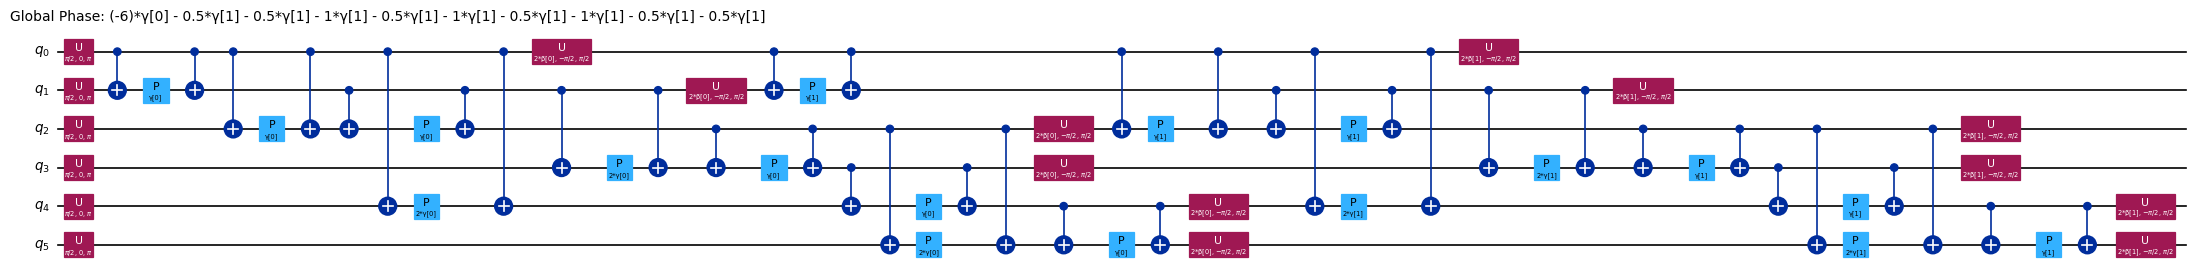

In [26]:
from qiskit.circuit.library import qaoa_ansatz

reps = 2
ansatz = qaoa_ansatz(H, reps=reps)
print("parameters:", ansatz.parameters)
ansatz.decompose(reps=2).draw("mpl", fold=-1, scale=0.6)

### 8.2 The $p=1$ energy landscape

We first evaluate $\langle H_C\rangle$ on a $(\gamma,\beta)$ grid for $p=1$. All parameter sets go into one **estimator PUB** as a parameter array. (A PUB, or primitive unified bloc, is a tuple of circuit, observables and parameter values [[10]](https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output).) So the grid needs only one primitive call.

p=1 parameter order: [ParameterVectorElement(β[0]), ParameterVectorElement(γ[0])]


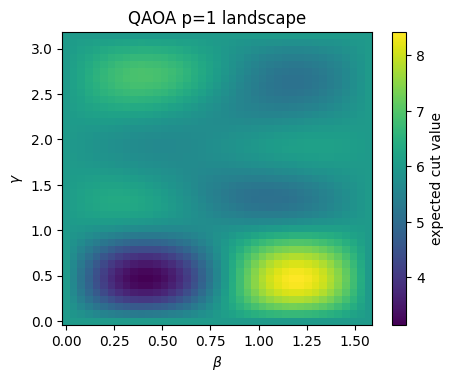

best grid point: gamma=0.471, beta=1.217, expected cut=8.417


In [27]:
from qiskit.primitives import StatevectorEstimator, StatevectorSampler

estimator = StatevectorEstimator()
ansatz_p1 = qaoa_ansatz(H, reps=1)
print("p=1 parameter order:", list(ansatz_p1.parameters))   # [beta, gamma] (alphabetical)

gammas = np.linspace(0, np.pi, 41)
betas = np.linspace(0, np.pi / 2, 41)
B, Gm = np.meshgrid(betas, gammas)
param_grid = np.stack([B, Gm], axis=-1)                        # shape (41, 41, 2)
energies = estimator.run([(ansatz_p1, H, param_grid)]).result()[0].data.evs + offset

fig, ax = plt.subplots(figsize=(5, 3.8))
im = ax.pcolormesh(betas, gammas, -energies, shading="auto", cmap="viridis")
fig.colorbar(im, ax=ax, label="expected cut value")
ax.set_xlabel(r"$\beta$"); ax.set_ylabel(r"$\gamma$"); ax.set_title("QAOA p=1 landscape")
plt.show()
i, j = np.unravel_index(np.argmin(energies), energies.shape)
print(f"best grid point: gamma={gammas[i]:.3f}, beta={betas[j]:.3f}, expected cut={-energies[i, j]:.3f}")

### 8.3 Variational optimization ($p=2$)

`qaoa_ansatz` sorts its parameters alphabetically: `β[0], β[1], γ[0], γ[1]`. We start from the best $p=1$ grid point and refine with COBYLA, a gradient-free optimizer from SciPy. We also run three random starting points.

optimal parameters: [1.0524 1.2533 0.3397 0.6424]
expected cut <C> = 9.5790  (optimum 11.0)
approximation ratio <C>/C_max = 0.871


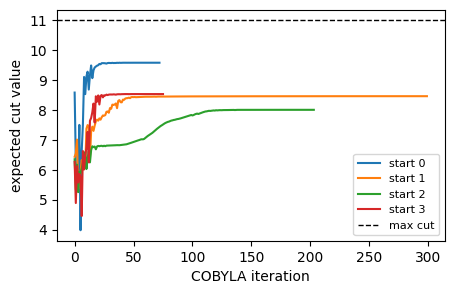

In [28]:
from scipy.optimize import minimize

trace = []
def cost(theta):
    e = estimator.run([(ansatz, H, theta)]).result()[0].data.evs
    trace.append(float(e) + offset)
    return float(e)

rng = np.random.default_rng(42)
starts = [np.array([betas[j], betas[j], gammas[i], gammas[i]])]           # interpolated p=1 seed
starts += [rng.uniform([0, 0, 0, 0], [np.pi / 2, np.pi / 2, np.pi, np.pi]) for _ in range(3)]

best = None
traces = []
for x0 in starts:
    trace = []
    r = minimize(cost, x0, method="COBYLA", options={"maxiter": 300})
    traces.append(trace)
    if best is None or r.fun < best.fun:
        best = r
print("optimal parameters:", np.round(best.x, 4))
print(f"expected cut <C> = {-(best.fun + offset):.4f}  (optimum {best_cut})")
print(f"approximation ratio <C>/C_max = {-(best.fun + offset) / best_cut:.3f}")

fig, ax = plt.subplots(figsize=(5, 3))
for k, tr in enumerate(traces):
    ax.plot(-np.array(tr), label=f"start {k}")
ax.axhline(best_cut, color="k", ls="--", lw=1, label="max cut")
ax.set_xlabel("COBYLA iteration"); ax.set_ylabel("expected cut value"); ax.legend(fontsize=8)
plt.show()

### 8.4 Sampling and interpreting the result

We add measurements, bind the optimal parameters and sample. Qiskit bitstrings are little-endian: qubit 0 is the rightmost character. `sample_most_likely` accepts a counts dict and reverses the order. So the returned array is indexed by variable.

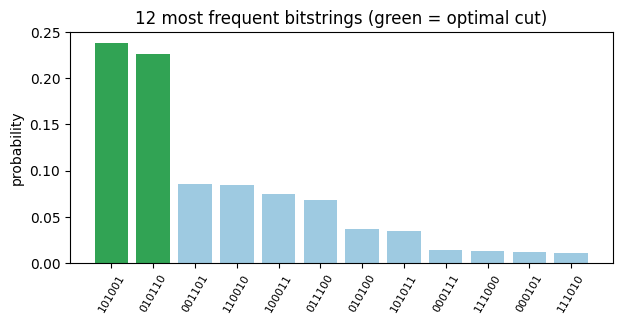

probability of sampling an optimal cut: 0.465  (random guessing: 0.031)
most likely x: [1 0 0 1 0 1] | partition: [[1, 2, 4], [0, 3, 5]] | cut value: 11.0


In [29]:
sampler = StatevectorSampler(seed=1234)
qc = ansatz.measure_all(inplace=False)
counts = sampler.run([(qc, best.x)], shots=4000).result()[0].data.meas.get_counts()

def cut_value(bitstring):
    xv = np.array([int(b) for b in reversed(bitstring)])
    return qp.objective.evaluate(xv)

top = sorted(counts.items(), key=lambda kv: -kv[1])[:12]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([b for b, _ in top], [c / 4000 for _, c in top],
       color=["#31a354" if np.isclose(cut_value(b), best_cut) else "#9ecae1" for b, _ in top])
ax.set_ylabel("probability"); ax.set_title("12 most frequent bitstrings (green = optimal cut)")
plt.xticks(rotation=60, fontsize=8)
plt.show()

p_opt = sum(c for b, c in counts.items() if np.isclose(cut_value(b), best_cut)) / 4000
print(f"probability of sampling an optimal cut: {p_opt:.3f}  (random guessing: "
      f"{np.sum(np.isclose(all_E, e_best)) / 2**6:.3f})")

x_qaoa = Maxcut.sample_most_likely(counts)
print("most likely x:", x_qaoa, "| partition:", maxcut.interpret(x_qaoa),
      "| cut value:", qp.objective.evaluate(x_qaoa))

We draw the cut. Node colors show the partition, and the cut edges are highlighted. `Maxcut.draw(x)` makes a similar picture with the matplotlib drawer of rustworkx.

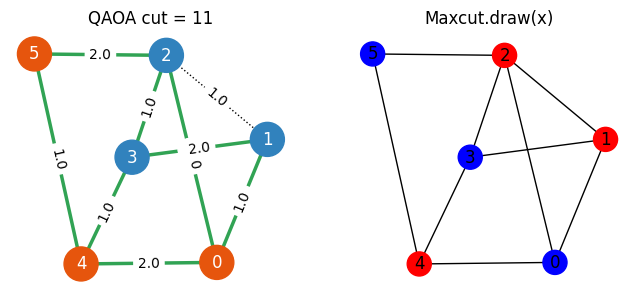

In [30]:
colors = ["#e6550d" if v else "#3182bd" for v in x_qaoa]
cut_edges = [(u, v) for u, v in Gw.edges if x_qaoa[u] != x_qaoa[v]]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
ax = axes[0]
nx.draw_networkx_nodes(Gw, pos_w, ax=ax, node_color=colors, node_size=600)
nx.draw_networkx_labels(Gw, pos_w, ax=ax, font_color="white")
nx.draw_networkx_edges(Gw, pos_w, ax=ax, edgelist=[e for e in Gw.edges if e not in cut_edges], style="dotted")
nx.draw_networkx_edges(Gw, pos_w, ax=ax, edgelist=cut_edges, width=2.5, edge_color="#31a354")
nx.draw_networkx_edge_labels(Gw, pos_w, ax=ax, edge_labels=nx.get_edge_attributes(Gw, "weight"))
ax.set_title(f"QAOA cut = {qp.objective.evaluate(x_qaoa):.0f}"); ax.axis("off")

plt.sca(axes[1])
maxcut.draw(x_qaoa, pos={k: v for k, v in pos_w.items()})
axes[1].set_title("Maxcut.draw(x)")
plt.show()

## 9. Summary and references

* `OptimizationProblem` models problems with **binary, integer, continuous and spin** variables. The objective can have constant, linear, quadratic and **higher-order** terms. Constraints can be linear, quadratic or higher order. `prettyprint`, `evaluate` and `is_feasible` help to inspect and check a model.
* `from_docplex_mp` and `to_docplex_mp` connect to docplex, including LP export. Higher-order terms and spin variables cannot be exported.
* `applications` provides ready-made models (MaxCut, Knapsack, TSP, vertex cover, independent set, ...) with `interpret` and `draw` helpers.
* Converters (`OptimizationProblemToQubo`, `OptimizationProblemToHubo` and their building blocks) remove constraints with slack variables and penalties. The **penalty factor** decides whether the unconstrained optimum is feasible. `interpret` maps solutions back.
* `to_ising` returns a `SparsePauliOp` and an offset. Maximization problems are negated, so the task is always a minimization.
* `ScipyMilpSolver` solves linear models for validation. CPLEX and Gurobi wrappers exist for quadratic models when those packages are installed.
* QAOA built from `qaoa_ansatz`, `StatevectorEstimator`, SciPy and `StatevectorSampler` solves small MaxCut instances. `sample_most_likely` and `interpret` decode the answer.

**Notes on the installed version (v0.1.0)**

* `OptimizationProblemToQubo` rejects higher-order objectives and constraints. Workaround: use `OptimizationProblemToHubo`. The resulting Ising operator can then contain many-body $Z$ strings.
* QUBO and HUBO conversion do not support continuous variables. Workaround: build a copy of the model with discrete variables only, as in Section 5.2.
* `ScipyMilpSolver.get_compatibility_msg` checks only quadratic objectives and quadratic constraints. It does not report higher-order terms. Check for higher-order terms yourself before calling the solver.
* `qaoa_ansatz` sorts its parameters alphabetically (`β` before `γ`). Order the initial point to match `ansatz.parameters`.

## References

1. How-to: Migrate from `qiskit-optimization` to `qiskit-addon-opt-mapper`. <https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/00_migrate_from_qiskit_optimization.html>
2. How-to: Model quantum optimization problems with the `OptimizationProblem` class. <https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/01_optimization_problem.html>
3. How-to: Translate between `OptimizationProblem` and Docplex. <https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/04_translate_docplex.html>
4. API reference: `qiskit_addon_opt_mapper.applications`. <https://qiskit.github.io/qiskit-addon-opt-mapper/apidocs/qiskit_addon_opt_mapper.applications.html>
5. How-to: Convert formulations of an `OptimizationProblem`. <https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/02_converters_for_optimization_problems.html>
6. API reference: `to_ising`. <https://qiskit.github.io/qiskit-addon-opt-mapper/stubs/qiskit_addon_opt_mapper.translators.to_ising.html>
7. How-to: Validate your modeling with classical solvers. <https://qiskit.github.io/qiskit-addon-opt-mapper/how_tos/03_validate_with_solvers.html>
8. API reference: `ScipyMilpSolver`. <https://qiskit.github.io/qiskit-addon-opt-mapper/stubs/qiskit_addon_opt_mapper.solvers.ScipyMilpSolver.html>
9. Qiskit API reference: `qaoa_ansatz`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.qaoa_ansatz>
10. IBM Quantum guide: Primitive inputs and outputs. <https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output>
11. Qiskit API reference: `StatevectorEstimator`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator>
12. Qiskit API reference: `StatevectorSampler`. <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler>